In [1]:
#All the imports
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.stats import norm
from scipy.stats import kurtosis
import fifpy

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.fields import compute_radial_spectrum
from shared.filtering import iterative_filtering1D, iterative_filtering3D
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("experiments", "IterativeFilteringCheck")

In [2]:

def partial_x_2d(f,dx):
    """Compute ∂f/∂x using 2nd-order central differences with periodic BCs."""
    Nx, Ny = f.shape
    df_dx = np.zeros_like(f)
    
    # Central difference in x-direction (axis=0)
    df_dx[1:Nx-1, :] = (f[2:Nx, :] - f[0:Nx-2, :]) / (2 * dx)
    
    # Periodic boundaries (x-direction)
    df_dx[0, :] = (f[1, :] - f[-1, :]) / (2 * dx)
    df_dx[-1, :] = (f[0, :] - f[-2, :]) / (2 * dx)
    
    return df_dx

def partial_y_2d(f,dy):
    """Compute ∂f/∂y using 2nd-order central differences with periodic BCs."""
    Nx, Ny = f.shape
    df_dy = np.zeros_like(f)
    
    # Central difference in y-direction (axis=1)
    df_dy[:, 1:Ny-1] = (f[:, 2:Ny] - f[:, 0:Ny-2]) / (2 * dy)
    
    # Periodic boundaries (y-direction)
    df_dy[:, 0] = (f[:, 1] - f[:, -1]) / (2 * dy)
    df_dy[:, -1] = (f[:, 0] - f[:, -2]) / (2 * dy)
    
    return df_dy

def partial_x_fft(f, dx):
    """
    Calculate ∂f/∂x using FFT on a 2D grid.

    Parameters:
        f (2D np.array): Function values on a 2D grid (shape: Nx × Ny).
        dx (float): Grid spacing in the x-direction.

    Returns:
        df_dx (2D np.array): Partial derivative ∂f/∂x.
    """
    nx, ny = f.shape
    kx = np.fft.fftfreq(nx, d=dx) * 2 * np.pi  # Wavenumbers in x
    kx = kx[:, np.newaxis]                     # Make it 2D for broadcasting

    f_hat = np.fft.fft2(f)
    df_dx_hat = 1j * kx * f_hat
    df_dx = np.fft.ifft2(df_dx_hat).real

    return np.array(df_dx)

def partial_y_fft(f, dy):
    """
    Calculate ∂f/∂y using FFT on a 2D grid.

    Parameters:
        f (2D np.array): Function values on a 2D grid (shape: Nx × Ny).
        dy (float): Grid spacing in the y-direction.

    Returns:
        df_dy (2D np.array): Partial derivative ∂f/∂y.
    """
    nx, ny = f.shape
    ky = np.fft.fftfreq(ny, d=dy) * 2 * np.pi  # Wavenumbers in y
    ky = ky[np.newaxis, :]                     # Make it 2D for broadcasting

    f_hat = np.fft.fft2(f)
    df_dy_hat = 1j * ky * f_hat
    df_dy = np.fft.ifft2(df_dy_hat).real

    return df_dy

#Denoising the data
def gaussian_fft_filter_2d(J_squared, k0):
    """
    Apply a Gaussian low-pass filter in Fourier space to a 2D field.

    Parameters
    ----------
    J_squared : 2D numpy array
        Input real-space data
    k0 : float
        Filter width in k-space (grid units). Smaller = stronger smoothing.

    Returns
    -------
    J_filtered : 2D numpy array
        Smoothed real-space data
    """

    # FFT
    F = np.fft.fft2(J_squared)
    F_shifted = np.fft.fftshift(F)

    # k-grid
    nx, ny = J_squared.shape
    kx = np.fft.fftshift(np.fft.fftfreq(nx)) * nx
    ky = np.fft.fftshift(np.fft.fftfreq(ny)) * ny
    KX, KY = np.meshgrid(kx, ky, indexing='ij')
    K2 = KX**2 + KY**2

    # Gaussian filter in k-space
    gaussian = np.exp(-K2 / (2 * k0**2))

    # Apply filter
    F_filt = F_shifted * gaussian

    # Inverse FFT
    F_filt = np.fft.ifftshift(F_filt)
    J_filtered = np.fft.ifft2(F_filt)

    # Return real part
    return np.real(J_filtered)




In [3]:
# List of simulation directories

dx = 0.0625
dy = 0.0625

# dx = 0.125
# dy = 0.125

In [4]:
# # Plotting Power Spectrum at reconnection time

# base_path = "/home/UNN/w24021992/NAS/simulations_beta_scan/beta_p_16/beta_e_1"

# time = 250

# File_Bx = f"{base_path}/Bx_ApJ_t{time}.h5"


# with h5py.File(File_Bx, 'r') as fBx:
#     data_Bx = fBx['DS1'][:].T


# # Compute radial spectra
# spectrum_Bx = compute_radial_spectrum(data_Bx, dx, dy)

In [5]:
#Spectrum after filtering

# data_Bx_filtered = iterative_filtering(data_Bx)
# data_Bx_filtered = gaussian_fft_filter_2d(data_Bx, k0=0.1 * len(data_Bx))
# data_Bx_filtered = iterative_filtering(data_Bx,3)
# spectrum_Bxf = compute_radial_spectrum(data_Bx_filtered, dx, dy)

IMF 1
IMF 2
IMF 3
IMF 4
(5, 4096, 4096)


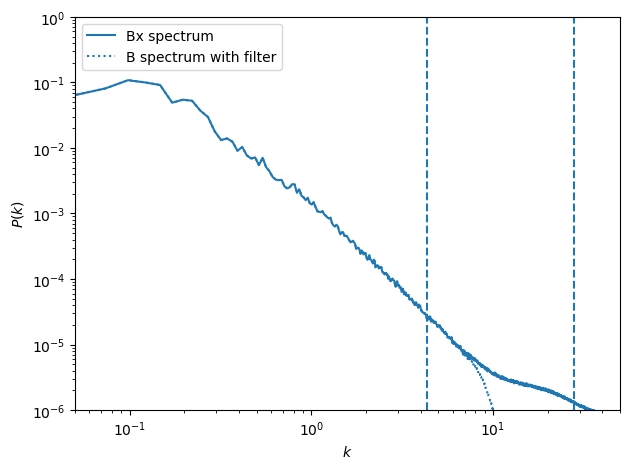

In [6]:
# # Plot unfiltered first and capture line objects

# line_B, = plt.loglog(
#     spectrum_Bx.kk,
#     spectrum_Bx.sp,
#     label="Bx spectrum"
# )

# plt.loglog(
#     spectrum_Bxf.kk,
#     spectrum_Bxf.sp,
#     linestyle=":",
#     color=line_B.get_color(),
#     label="B spectrum with filter"
# )

# plt.xlabel(r"$k$")
# plt.ylabel(r"$P(k)$")
# plt.xlim(5e-2, 50)
# plt.ylim(1e-6, 1)
# plt.axvline(x=4.3192, linestyle='--')
# plt.axvline(x=28, linestyle='--')

# plt.legend()
# plt.tight_layout()
# plt.savefig("JB_Spectrum", dpi=300)
# plt.show()

In [12]:
# Plotting Power Spectrum at reconnection time

base_path = f"{DATA_ROOT}/beta_p_0.25/beta_e_1"
# base_path = "/DATA/QMUL/data-franci/data/RunCompa_2Dbig_rms012_modes8"


time = 200
sim_tag = 'ApJ'
# sim_tag = 'EL8modes'

File_Bx = f"{base_path}/Bx_{sim_tag}_t{time}.h5"
File_By = f"{base_path}/By_{sim_tag}_t{time}.h5"
File_Bz = f"{base_path}/Bz_{sim_tag}_t{time}.h5"


with h5py.File(File_Bx, 'r') as fBx, \
         h5py.File(File_By, 'r') as fBy, \
         h5py.File(File_Bz, 'r') as fBz:

        data_Bx = fBx['DS1'][:].T
        data_By = fBy['DS1'][:].T
        data_Bz = fBz['DS1'][:].T


data_Jx =  partial_y_fft(data_Bz, dx)
data_Jy = -partial_x_fft(data_Bz, dx)
data_Jz =  partial_x_fft(data_By, dx) - partial_y_fft(data_Bx, dx)

# Compute radial spectra
spectrum_Bx = compute_radial_spectrum(data_Bx, dx, dy)
spectrum_By = compute_radial_spectrum(data_By, dx, dy)
spectrum_Bz = compute_radial_spectrum(data_Bz, dx, dy)

spectrum_Jx = compute_radial_spectrum(data_Jx, dx, dy)
spectrum_Jy = compute_radial_spectrum(data_Jy, dx, dy)
spectrum_Jz = compute_radial_spectrum(data_Jz, dx, dy)

spectrum_B = np.recarray(spectrum_Bx.shape, dtype=spectrum_Bx.dtype)
spectrum_B.kk = spectrum_Bx.kk
spectrum_B.sp = spectrum_Bx.sp + spectrum_By.sp + spectrum_Bz.sp

spectrum_J = np.recarray(spectrum_Jx.shape, dtype=spectrum_Jx.dtype)
spectrum_J.kk = spectrum_Jx.kk
spectrum_J.sp = spectrum_Jx.sp + spectrum_Jy.sp + spectrum_Jz.sp

In [13]:
# data_Bx_filtered = iterative_filtering(data_Bx,3)
# data_By_filtered = iterative_filtering(data_By,3)
# data_Bz_filtered = iterative_filtering(data_Bz,3)

data_Bx_filtered, data_By_filtered, data_Bz_filtered = iterative_filtering3D(data_Bx, data_By, data_Bz, 3, Xi=2.3)

IMF 1
IMF 2
IMF 3
IMF 4
IMF 1
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 4
input mask not integer, making it so
IMF 1
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 4
input mask not integer, making it so


In [14]:
spectrum_Bxf = compute_radial_spectrum(data_Bx_filtered, dx, dy)
spectrum_Byf = compute_radial_spectrum(data_By_filtered, dx, dy)
spectrum_Bzf = compute_radial_spectrum(data_Bz_filtered, dx, dy)

spectrum_Bf = np.recarray(spectrum_Bxf.shape, dtype=spectrum_Bxf.dtype)
spectrum_Bf.kk = spectrum_Bxf.kk
spectrum_Bf.sp = spectrum_Bxf.sp + spectrum_Byf.sp + spectrum_Bzf.sp

data_Jx_filtered = partial_y_fft(data_Bz_filtered,dx)
data_Jy_filtered = -partial_x_fft(data_Bz_filtered,dy)
data_Jz_filtered = partial_x_fft(data_By_filtered,dy)-partial_y_fft(data_Bx_filtered,dx)

spectrum_Jxf = compute_radial_spectrum(data_Jx_filtered, dx, dy)
spectrum_Jyf = compute_radial_spectrum(data_Jy_filtered, dx, dy)
spectrum_Jzf = compute_radial_spectrum(data_Jz_filtered, dx, dy)

spectrum_Jf = np.recarray(spectrum_Jxf.shape, dtype=spectrum_Jxf.dtype)
spectrum_Jf.kk = spectrum_Jxf.kk
spectrum_Jf.sp = spectrum_Jxf.sp + spectrum_Jyf.sp + spectrum_Jzf.sp

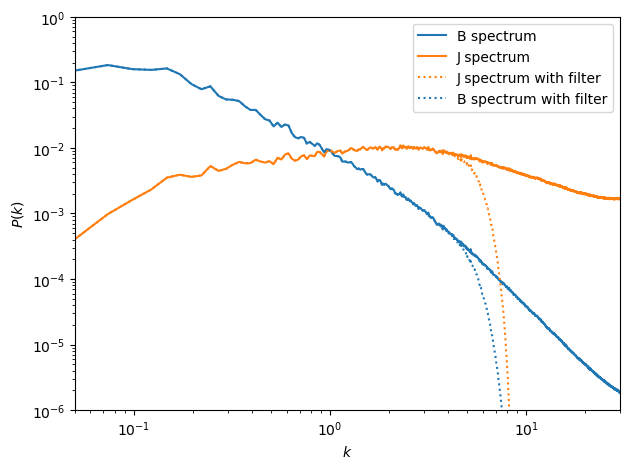

In [15]:
# Plot unfiltered first and capture line objects

line_B, = plt.loglog(
    spectrum_B.kk,
    spectrum_B.sp,
    label="B spectrum"
)

line_J, = plt.loglog(
    spectrum_J.kk,
    spectrum_J.sp,
    label="J spectrum"
)

plt.loglog(
    spectrum_Jf.kk,
    spectrum_Jf.sp,
    linestyle=":",
    color=line_J.get_color(),
    label="J spectrum with filter"
)

plt.loglog(
    spectrum_Bf.kk,
    spectrum_Bf.sp,
    linestyle=":",
    color=line_B.get_color(),
    label="B spectrum with filter"
)

plt.xlabel(r"$k$")
plt.ylabel(r"$P(k)$")
plt.xlim(5e-2, 30)
plt.ylim(1e-6, 1)
# plt.axvline(x=38.5105, linestyle='--', color='red', label='kdi at SNR=3')

plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "JB_Spectrum", dpi=300)
plt.show()